> Measure how much a model's forecasts move across cross-validation cutoffs, and whether those revisions were worth making.

## What you'll learn

- Why accuracy metrics cannot tell a steady forecaster from an erratic one
- How `forecast_percentage_change` (sFPC) measures how much forecasts are revised
- How `excess_volatility` (sEV) separates revisions that buy accuracy from ones that do not
- How to read the per-cutoff output and recover a single number over the whole cross-validation

## Motivation

Accuracy is usually the headline metric for a forecasting model, but it is not the only thing that matters in production.

A multi-horizon system running on a schedule produces several overlapping forecasts for the same future target date, one from each **forecast creation date**, as more data becomes available. In cross-validation output that date is the `cutoff` column. That sequence of updates is a **forecast revision**, and how consistent or erratic those revisions are is what we call **forecast volatility**.

Consider an electrical grid operator using load forecasts to plan power supply. A forecast that revises from 45 GW to 65 GW ahead of a heat wave is a *useful* revision: it tells operators to activate reserve plants. But forecasts that jump around erratically between cutoffs, without new information justifying the change, undermine trust and complicate planning. The goal is not to eliminate revisions. It is to distinguish benign, informative revisions from excessive, erratic ones.

Accuracy metrics cannot make that distinction: metrics such as `mae` and `scaled_crps` score each forecast against the truth and average, which discards the relationship *between* forecasts of the same date. Two models can post identical accuracy while one is steady and the other thrashes.

Part 1 applies the two volatility metrics to two hand-built forecasters that accuracy metrics cannot tell apart. Part 2 applies them, through `evaluate`, to the `cross_validation` output of StatsForecast and NeuralForecast models.

## The metrics

Both metrics compare the two forecasts that land on the **same target date** from consecutive cutoffs. Indexing by series $b$, cutoff $t$ and horizon step $h$, those are:

- $\hat{\mathbf{y}}_{b,t,h+1}$, issued at cutoff $t$, looking $h+1$ steps ahead
- $\hat{\mathbf{y}}_{b,t+1,h}$, issued at the next cutoff, looking $h$ steps ahead

The second is a revision of the first.

### Symmetric Forecast Percentage Change (sFPC)

sFPC measures the relative change in the forecasts across consecutive cutoffs, giving a quantitative view of the forecast revision rate:

$$\mathrm{sFPC} = \frac{200}{B \times T \times H} \sum_{b,t,h} \frac{|\hat{y}_{b,t+1,h}-\hat{y}_{b,t,h+1}|}{|\hat{y}_{b,t+1,h}| + |\hat{y}_{b,t,h+1}|}$$

Inspired by sMAPE, the denominator is symmetric in the two forecasts. This keeps the metric well behaved when predicted values are small and avoids the division-by-zero problems common to traditional percentage-based metrics.

### Scaled Excess Volatility (sEV)

sFPC treats every revision as equally undesirable, even ones that clearly improve accuracy. sEV instead penalises only revisions that move a forecast *away* from the truth, or that overshoot it:

$$\mathrm{EV}(y,\;\hat{\mathbf{y}}_1,\; \hat{\mathbf{y}}_2) = \mathrm{QL}(\hat{\mathbf{y}}_2,\hat{\mathbf{y}}_1) - \big(\mathrm{QL}(y,\hat{\mathbf{y}}_1)-\mathrm{QL}(y,\hat{\mathbf{y}}_2)\big)$$

$$\mathrm{sEV} = \frac{\sum_{b,t,h}\mathrm{EV}\big(y_{b,t,h},\;\hat{\mathbf{y}}_{b,t,h+1},\;\hat{\mathbf{y}}_{b,t+1,h}\big)}{\sum_{b,t,h}|y_{b,t,h}|}$$

where $\mathrm{QL}$ is the quantile loss, averaged over the quantile levels $q$ of the forecast:

$$\mathrm{QL}_q(y, \hat{y}^{(q)}) = q(y-\hat{y}^{(q)})_+ + (1-q)(\hat{y}^{(q)}-y)_+$$

The first EV term is what the revision cost; the bracketed term is the accuracy it bought. Because $\mathrm{QL}$ obeys the triangle inequality the second can never exceed the first, so $\mathrm{EV} \geq 0$. It is zero for a revision that moves straight toward the truth without overshooting it, and positive for one that moves away from the truth or overshoots it.

### Inputs and outputs

- `excess_volatility` needs a probabilistic forecast: a mapping from each model to its quantile columns, plus the matching `quantiles`. `forecast_percentage_change` is a point metric: pass a point forecast, or the median of a probabilistic one, since the outer quantiles are expected to move inward as uncertainty shrinks.
- Both need **overlapping** windows. If `step_size` is greater than or equal to the horizon, each date is forecast only once and there is no revision to measure, so both raise an error.
- Like the other losses, both return **one row per series and cutoff**. A row scores the revisions made *at* that cutoff, so the first cutoff of each series is empty: there is nothing before it to revise.
- sFPC rows are means over that cutoff's pairs. sEV rows divide that cutoff's EV by a scale shared by all cutoffs of the series: $\sum |y|$ over all of its pairs, divided by the number of cutoffs that have pairs. Either way, **averaging a series' rows over cutoffs gives its value over the whole cross-validation**. The cost of the shared scale is that adding or removing a cutoff changes the sEV of the other cutoffs of that series.

## Install libraries

In [ ]:
%%capture
pip install utilsforecast statsforecast neuralforecast matplotlib -U

In [2]:
import logging
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from neuralforecast import NeuralForecast
from neuralforecast.losses.pytorch import MQLoss
from neuralforecast.models import MLP, NHITS
from neuralforecast.utils import AirPassengersPanel
from statsforecast import StatsForecast
from statsforecast.models import AutoETS, SeasonalNaive
from statsforecast.utils import AirPassengersDF

from utilsforecast.evaluation import evaluate
from utilsforecast.losses import (
    excess_volatility,
    forecast_percentage_change,
    mae,
    scaled_crps,
)

logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)
logging.getLogger("lightning_fabric").setLevel(logging.ERROR)

## 1. Two forecasters that accuracy cannot tell apart

To see why a volatility metric is needed at all, we build two forecasters by hand and give them the *same* accuracy.

The series is a week of hourly demand with a daily shape and a weekday/weekend effect. We forecast it from six cutoffs spaced 24 hours apart, each with a 48 hour horizon, so every window overlaps the next by 24 hours.

In [3]:
HORIZON = 48
STEP_SIZE = 24
N_HOURS = 168
STARTS = [0, 24, 48, 72, 96, 120]  # first forecasted hour of each window

QUANTILES = [0.1, 0.25, 0.4, 0.5, 0.6, 0.75, 0.9]
BAND = 3.5
# half-width of each quantile relative to the median, as a multiple of BAND
SPREAD = {0.1: 1.0, 0.25: 0.55, 0.4: 0.25, 0.5: 0.0, 0.6: -0.25, 0.75: -0.55, 0.9: -1.0}

hours = np.arange(N_HOURS)
times = pd.date_range("2024-01-01", periods=N_HOURS, freq="h")


def daily_shape(h):
    t = (h % 24) / 24
    return (
        40
        + 18 * np.sin(np.pi * (t - 0.05))
        + 10 * np.exp(-((t - 0.83) ** 2) / 0.01)
        - 6 * np.exp(-((t - 0.15) ** 2) / 0.008)
    )


weekday_effect = np.array([1.0, 1.02, 1.03, 1.02, 1.04, 0.92, 0.88])[hours // 24]
truth = daily_shape(hours) * weekday_effect + np.random.default_rng(7).normal(0, 0.5, N_HOURS)

The two forecasters differ only in **where their error comes from**.

The *steady* forecaster is wrong in a way that persists: it draws one error signal for the whole week, so every cutoff is wrong about a given date in the same direction. Its forecasts for a shared date barely move.

The *erratic* forecaster draws fresh, independent error at every cutoff, and additionally flips the sign of a shift on the overlapping half of each window. Its forecasts for a shared date swing back and forth.

In [4]:
# steady: one persistent error signal shared by every cutoff, plus a little jitter
rng = np.random.default_rng(13)
persistent_error = rng.normal(0, 2.65, N_HOURS)
steady_medians = [
    truth[s : s + HORIZON] + persistent_error[s : s + HORIZON] + rng.normal(0, 0.8, HORIZON)
    for s in STARTS
]

# erratic: fresh error each cutoff, plus a sign-flipping shift on the overlapping half
rng = np.random.default_rng(77)
erratic_medians = []
for i, s in enumerate(STARTS):
    shift = np.zeros(HORIZON)
    shift[HORIZON // 2 :] = (-1) ** i * 3.0
    erratic_medians.append(truth[s : s + HORIZON] + rng.normal(0, 2.0, HORIZON) + shift)

The metrics take the same long format that `cross_validation` returns: one row per series, cutoff and target date, with the actual `y` and one column per forecast. We store each forecaster as its own series, with one column per quantile.

In [5]:
QUANTILE_COLS = [f"q{int(100 * q)}" for q in QUANTILES]


def to_cv_df(unique_id, medians):
    windows = []
    for start, median in zip(STARTS, medians):
        window = pd.DataFrame(
            {
                "unique_id": unique_id,
                "ds": times[start : start + HORIZON],
                "cutoff": times[start] - pd.Timedelta(hours=1),
                "y": truth[start : start + HORIZON],
            }
        )
        for q, col in zip(QUANTILES, QUANTILE_COLS):
            window[col] = median - SPREAD[q] * BAND
        windows.append(window)
    return pd.concat(windows, ignore_index=True)


cv_df = pd.concat(
    [to_cv_df("steady", steady_medians), to_cv_df("erratic", erratic_medians)],
    ignore_index=True,
)
cv_df.head()

,unique_id,ds,cutoff,y,q10,q25,q40,q50,q60,q75,q90
0,steady,2024-01-01 00:00:00,2023-12-31 23:00:00,36.824467,37.183181,38.758181,39.808181,40.683181,41.558181,42.608181,44.183181
1,steady,2024-01-01 01:00:00,2023-12-31 23:00:00,38.294509,26.842077,28.417077,29.467077,30.342077,31.217077,32.267077,33.842077
2,steady,2024-01-01 02:00:00,2023-12-31 23:00:00,38.301923,37.711928,39.286928,40.336928,41.211928,42.086928,43.136928,44.711928
3,steady,2024-01-01 03:00:00,2023-12-31 23:00:00,38.207628,35.238030,36.813030,37.863030,38.738030,39.613030,40.663030,42.238030
4,steady,2024-01-01 04:00:00,2023-12-31 23:00:00,40.428046,40.427446,42.002446,43.052446,43.927446,44.802446,45.852446,47.427446


Plotting the six forecast windows against the truth makes the difference obvious.

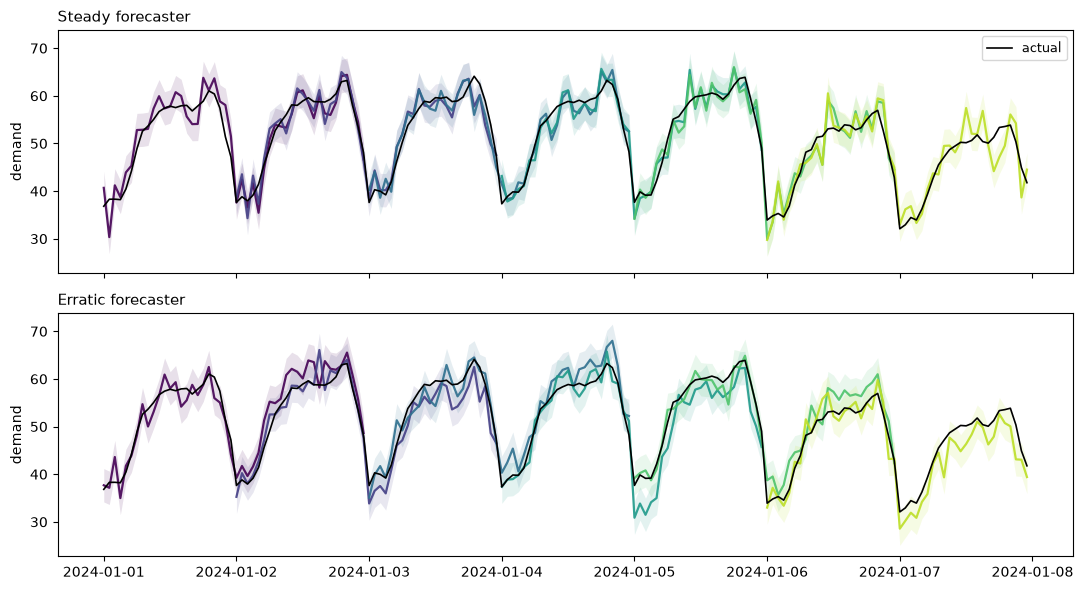

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, sharey=True)
colors = plt.cm.viridis(np.linspace(0, 0.9, len(STARTS)))

for ax, unique_id in zip(axes, ["steady", "erratic"]):
    ax.plot(times, truth, color="black", linewidth=1.2, label="actual", zorder=5)
    series = cv_df[cv_df["unique_id"] == unique_id]
    for color, (_, window) in zip(colors, series.groupby("cutoff")):
        ax.plot(window["ds"], window["q50"], color=color, linewidth=1.6, alpha=0.9)
        ax.fill_between(
            window["ds"], window["q10"], window["q90"], color=color, alpha=0.12, linewidth=0
        )
    ax.set_title(f"{unique_id.capitalize()} forecaster", loc="left", fontsize=11)
    ax.set_ylabel("demand")

axes[0].legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

Now score them. Every metric returns one row per series and cutoff, so we average each series over its cutoffs to get one number for the whole cross-validation. The first cutoff of the volatility metrics is empty, and `mean` skips it.

In [7]:
models = {"model": QUANTILE_COLS}
quantiles = np.array(QUANTILES)


def per_series(res, col):
    return res.groupby("unique_id")[col].mean()


scores = pd.DataFrame(
    {
        "MAE": per_series(mae(cv_df, ["q50"]), "q50"),
        "sCRPS": per_series(scaled_crps(cv_df, models, quantiles), "model"),
        "sFPC": per_series(forecast_percentage_change(cv_df, ["q50"]), "q50"),
        "sEV": per_series(excess_volatility(cv_df, models, quantiles), "model"),
    }
)
scores.round(4)

,MAE,sCRPS,sFPC,sEV
unique_id,,,,
erratic,2.3027,0.0347,6.3188,0.0200
steady,2.3132,0.0348,1.9327,0.0104


On accuracy the two are effectively tied: any comparison based on `MAE` or `sCRPS` would call this a wash. The volatility metrics are not. The erratic forecaster revises its median about three times as much as the steady one, and its scaled excess volatility is roughly double: the revisions it makes are not buying it accuracy.

This is the case for tracking volatility alongside accuracy rather than instead of it. The two measure different things, and a model can be good at one and bad at the other. Lower is better on both: the goal is to cut volatility without giving up accuracy.

The per-cutoff rows show *when* the revisions happened. Here the first cutoff is empty, and each later row scores the revisions made at that cutoff:

In [8]:
excess_volatility(cv_df, models, quantiles).pivot(
    index="cutoff", columns="unique_id", values="model"
).round(4)

unique_id,erratic,steady
cutoff,,
2023-12-31 23:00:00,NaN,NaN
2024-01-01 23:00:00,0.0186,0.0137
2024-01-02 23:00:00,0.0209,0.0111
2024-01-03 23:00:00,0.0175,0.0090
2024-01-04 23:00:00,0.0180,0.0102
2024-01-05 23:00:00,0.0247,0.0078


## 2. Volatility metrics on cross-validation output

In practice the forecasts come from a `cross_validation` call. Its output already has the long format the metrics take, so they plug straight into `evaluate` next to the accuracy metrics.

The one requirement is that **`step_size` must be smaller than the horizon**, so that windows overlap. In both examples below the horizon is 12 months and the windows start 4 months apart.

### StatsForecast

In [9]:
sf = StatsForecast(
    models=[AutoETS(season_length=12), SeasonalNaive(season_length=12)],
    freq="ME",
)
cv_df = sf.cross_validation(df=AirPassengersDF, h=12, n_windows=8, step_size=4, level=[80])
cv_df.head()

,unique_id,ds,cutoff,y,AutoETS,AutoETS-lo-80,AutoETS-hi-80,SeasonalNaive,SeasonalNaive-lo-80,SeasonalNaive-hi-80
0,1.0,1957-09-30,1957-08-31,404.0,394.742325,367.617583,421.867067,355.0,311.806852,398.193148
1,1.0,1957-10-31,1957-08-31,347.0,345.176478,316.961525,373.391430,306.0,262.806852,349.193148
2,1.0,1957-11-30,1957-08-31,305.0,297.579707,268.580777,326.578636,271.0,227.806852,314.193148
3,1.0,1957-12-31,1957-08-31,336.0,336.689816,306.716914,366.662719,306.0,262.806852,349.193148
4,1.0,1958-01-31,1957-08-31,340.0,344.637917,313.677068,375.598766,315.0,271.806852,358.193148


`evaluate` builds the quantile columns of `excess_volatility` from `level`, and passes the point forecast to `forecast_percentage_change`:

In [10]:
evaluation = evaluate(
    cv_df,
    metrics=[mae, scaled_crps, forecast_percentage_change, excess_volatility],
    level=[80],
)
evaluation[evaluation["metric"] == "excess_volatility"].round(4)

,unique_id,cutoff,metric,AutoETS,SeasonalNaive
24,1.0,1957-08-31,excess_volatility,NaN,NaN
25,1.0,1957-12-31,excess_volatility,0.0023,0.0007
26,1.0,1958-04-30,excess_volatility,0.0268,0.0000
27,1.0,1958-08-31,excess_volatility,0.0356,0.0001
28,1.0,1958-12-31,excess_volatility,0.0116,0.0006
29,1.0,1959-04-30,excess_volatility,0.0000,0.0002
30,1.0,1959-08-31,excess_volatility,0.0267,0.0014
31,1.0,1959-12-31,excess_volatility,0.0036,0.0018


As in Part 1, averaging over cutoffs gives one number per metric for the whole cross-validation:

In [11]:
evaluation.groupby("metric")[["AutoETS", "SeasonalNaive"]].mean().round(4)

,AutoETS,SeasonalNaive
metric,,
excess_volatility,0.0152,0.0007
forecast_percentage_change,4.5195,0.0000
mae,31.9450,35.8438
scaled_crps,0.0358,0.0342


Read these together rather than separately. Accuracy tells you how close the forecasts land; `sFPC` tells you how much the model moves them between cutoffs; `sEV` tells you how much of that movement was wasted.

`SeasonalNaive` shows why low volatility is not the goal on its own. Its forecast for a date is the value from twelve months earlier, which every overlapping window already observes, so it never revises its point forecast and its sFPC is exactly zero. Its sEV is small but not zero because its prediction intervals still move as the residuals are re-estimated. A model that never revises also never reacts to new information: the aim is to cut volatility without giving up accuracy.

### NeuralForecast

The same works for NeuralForecast. With a probabilistic loss such as `MQLoss`, its point forecast is named `<model>-median`, while `evaluate` looks for the point forecast under the model name, so we rename it first.

In [12]:
kwargs = dict(
    h=12,
    input_size=24,
    max_steps=100,
    loss=MQLoss(level=[80]),
    random_seed=0,
    enable_progress_bar=False,
    enable_model_summary=False,
    logger=False,
)
nf = NeuralForecast(models=[NHITS(**kwargs), MLP(**kwargs)], freq="ME")
nf_cv_df = nf.cross_validation(
    df=AirPassengersPanel[["unique_id", "ds", "y"]], n_windows=8, step_size=4
)
nf_cv_df = nf_cv_df.rename(columns={"NHITS-median": "NHITS", "MLP-median": "MLP"})
nf_cv_df.head()

,unique_id,ds,cutoff,NHITS,NHITS-lo-80,NHITS-hi-80,MLP,MLP-lo-80,MLP-hi-80,y
0,Airline1,1957-09-30,1957-08-31,410.096588,401.663391,428.506561,414.602539,388.057800,444.586823,404.0
1,Airline1,1957-10-31,1957-08-31,352.369141,347.738098,388.882629,371.339386,348.326752,414.614685,347.0
2,Airline1,1957-11-30,1957-08-31,320.527954,306.704224,360.734009,340.802216,324.927032,394.497101,305.0
3,Airline1,1957-12-31,1957-08-31,346.741974,295.041199,375.972443,351.276001,313.689301,372.324951,336.0
4,Airline1,1958-01-31,1957-08-31,371.886078,327.905975,393.153717,371.964417,336.879364,386.648651,340.0


In [13]:
nf_evaluation = evaluate(
    nf_cv_df,
    metrics=[mae, scaled_crps, forecast_percentage_change, excess_volatility],
    level=[80],
)
nf_evaluation.groupby("metric")[["NHITS", "MLP"]].mean().round(4)

,NHITS,MLP
metric,,
excess_volatility,0.0161,0.0134
forecast_percentage_change,3.2576,2.3368
mae,30.9373,31.2965
scaled_crps,0.0300,0.0327


Here the averages are over both series and all cutoffs.

## References

- Willa Potosnak, Malcolm Wolff, Mengfei Cao, Ruijun Ma, Tatiana Konstantinova, Dmitry Efimov, Michael W. Mahoney, Boris Oreshkin, Kin G. Olivares. [Forking-Sequences: Statistically and Computationally Efficient Multi-Horizon Forecasting with Reduced Volatility](https://openreview.net/forum?id=dXdycy7WCX). Transactions on Machine Learning Research (2026).